# Motif 8 split into 32 halves, then refined twice

This is the saved dictionary `SOCAL_H_76_230427_014845.x.limited_overlap_k1_w40_pc5_tau04_m8x32_refine2`, on the GPL whitened spectrogram of `SOCAL_H_76_230427_014845.x`.

It starts from `SOCAL_H_76_230427_014845.x.limited_overlap_k1_w40_pc5_tau04`, which has 9 motifs. Motif 8 of that dictionary, 1060 placements wide, is absent here. In its place are motifs whose ids run from 18 through 49: 32 ids, of which 27 are still present. The other eight motifs are kept. Each motif has 5 components. The summary records two refine iterations (`refine_iters` 2) and stops with reason `refine`.

The learning knobs are `k` 1, widths 10 to 40, `m` 10, `tau` 0.4, at least 10 placements, and `eps` 0.01.

Before specificity, each motif's dot-product sequence is shifted and scaled by a one-minute Gaussian mean and standard deviation. The number for a motif is the 90th percentile of the peak-to-baseline ratios of that sequence. A ratio is the shifted value at a local maximum divided by the same sequence after a shorter Gaussian smoothing, with standard deviation equal to half the motif width. Every finite ratio is included. The kernel is the leading component.

Output directory: `/home/yfreund/whale_processing/result/LeiData/SOCAL_H_76_230427_014845.x.limited_overlap_k1_w40_pc5_tau04_m8x32_refine2`.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from analysis.GPL_Python.gpl_outputs import display_from_spwhiten
from analysis.dict_learning.code.io import discover_windows
from analysis.evaluation.core import _dot_products, _peak_ratios, _specificity_p90

OUT = Path(
    "/home/yfreund/whale_processing/result/LeiData/"
    "SOCAL_H_76_230427_014845.x.limited_overlap_k1_w40_pc5_tau04_m8x32_refine2"
)
GPL = Path(
    "/home/yfreund/whale_processing/result/LeiData/"
    "SOCAL_H_76_230427_014845.x.gpl/output/spectrogram_npy"
)
summary = json.loads((OUT / "summary.json").read_text())
matchings = json.loads((OUT / "matchings.json").read_text())
counts = np.load(OUT / "counts.npz")
windows = discover_windows(GPL)
windows.sort(key=lambda window: (window.start_sample, window.window_id))
sec_per_bin = float(windows[0].overlap) / float(windows[0].sample_freq)
knobs = summary["knobs"]

offsets = {}
parts = []
cursor = 0
for window in windows:
    data = np.asarray(window.data, dtype=np.float64)
    offsets[window.window_id] = cursor
    parts.append(data)
    cursor += data.shape[1]
spectrogram = np.concatenate(parts, axis=1)

freq_axis = np.linspace(0.0, float(windows[0].sample_freq) / 2.0, int(windows[0].fftl) // 2)
i0 = int(np.argmin(np.abs(freq_axis - float(windows[0].start_freq))))
freqs = freq_axis[i0 : i0 + spectrogram.shape[0]]
band = np.flatnonzero(freqs <= 1500.0)
band_lo, band_hi = int(band[0]), int(band[-1]) + 1
f_lo, f_hi = float(freqs[band_lo]), float(freqs[band_hi - 1])

counts_kept = [row["n_placements"] for row in summary["motifs"]]
ratio = max(counts_kept) / min(counts_kept)
unexplained = np.array([row["unexplained"] for row in matchings], dtype=np.float64)
print(f"stop {summary['stop_reason']}")
print(
    f"coverage {summary['coverage']:.3f}  "
    f"({summary['n_bins_covered']} / {summary['n_bins_total']} columns)  "
    f"motifs {summary['n_motifs']}  placements {summary['n_placements']}  "
    f"max count {summary['max_count']}"
)
print(f"placement counts {min(counts_kept)} to {max(counts_kept)}  ratio {ratio:.3f}")
print(
    f"unexplained fraction  median {np.median(unexplained):.4f}  "
    f"mean {unexplained.mean():.4f}"
)
print("motif  placements  width  components")
for row in sorted(summary["motifs"], key=lambda item: item["motif_id"]):
    print(
        f"  {row['motif_id']:4d}  {row['n_placements']:6d}  "
        f"{row['width']:4d}  {row['n_components']:4d}"
    )

shift_sigma = 60.0 / sec_per_bin
summary["specificity"] = []
for row in summary["motifs"]:
    kernel = np.load(OUT / row["path"])
    if kernel.ndim == 3:
        kernel = kernel[0]
    ratios, percentile = _specificity_p90(
        _peak_ratios(_dot_products(spectrogram, kernel), float(row["width"] // 2), shift_sigma)
    )
    summary["specificity"].append(
        {
            "motif_id": row["motif_id"],
            "k": row["width"] // 2,
            "p90": None if not np.isfinite(percentile) else float(percentile),
            "n": int(ratios.size),
        }
    )
print("specificity  motif  k  p90  n")
for row in summary["specificity"]:
    print(f"  {row['motif_id']:4d}  {row['k']:3d}  {row['p90']:.4f}  {row['n']}")


stop refine
coverage 0.761  (13901 / 18270 columns)  motifs 35  placements 1336  max count 1
placement counts 10 to 67  ratio 6.700
unexplained fraction  median 0.2101  mean 0.2019
motif  placements  width  components
     0      28    13     5
     1      50    10     5
     3      42    13     5
    10      12    15     5
    11      10    14     5
    13      11    16     5
    14      21    11     5
    17      18    18     5
    18      41    10     5
    19      44    10     5
    20      52    10     5
    21      64    10     5
    22      40    10     5
    23      33    10     5
    24      43    10     5
    25      42    10     5
    26      44    10     5
    27      43    10     5
    28      40    10     5
    29      38    10     5
    30      44    10     5
    31      41    10     5
    32      35    10     5
    33      43    10     5
    35      49    10     5
    36      50    10     5
    38      38    10     5
    39      42    10     5
    40      47    10     5

specificity  motif  k  p90  n
     0    6  3.1912  2434
     1    5  2.9328  2901
     3    6  3.2310  2123
    10    7  3.1979  3187
    11    7  3.7880  2978
    13    8  4.5497  2739
    14    5  2.7157  2056
    17    9  3.2283  2286
    18    5  5.8079  4382
    19    5  3.1480  3942
    20    5  5.5899  4203
    21    5  5.5103  4029
    22    5  6.1690  3766
    23    5  4.2273  3916
    24    5  6.0391  3956
    25    5  5.9830  4134
    26    5  4.1332  3869
    27    5  4.7860  3655
    28    5  3.5502  4009
    29    5  5.4526  3845
    30    5  6.4717  3956
    31    5  2.7647  3247
    32    5  3.3300  3718
    33    5  4.2821  3399
    35    5  3.1291  3065
    36    5  3.8906  3458
    38    5  3.5501  3876
    39    5  3.0404  3819
    40    5  4.5990  3522
    41    5  4.5259  3895
    42    5  4.4222  3607
    43    5  4.4253  3789
    44    5  3.1668  3392
    46    5  3.8568  3110
    49    5  2.5981  2595


## Residual and runner-up

For each placement, every other motif is scored on a patch of its own width that starts at the same column and stays inside the window. The residual is the unexplained fraction after the mean plus five components. The runner-up is the other motif with the smallest residual. The gap is that residual minus the assigned motif's residual. Each row is the median over the motif's placements. The runner-up column is the motif that is the runner-up most often.


In [2]:
from analysis.evaluation.core import _load_basis, _residual_summary

models = {row["motif_id"]: _load_basis(str(OUT / row["path"])) for row in summary["motifs"]}
widths = {row["motif_id"]: int(row["width"]) for row in summary["motifs"]}
placements = [
    (row["motif_id"], offsets[row["window_id"]] + int(row["t_start"]), widths[row["motif_id"]])
    for row in matchings
]
scored = _residual_summary(spectrogram, offsets, placements, models)
print(f"{'motif':>6} {'n':>4} {'median residual':>16} {'median gap':>12} {'runner-up':>10}")
for motif_id, row in sorted(scored["motifs"].items()):
    print(
        f"{motif_id:6d} {row['n_placements']:4d} "
        f"{row['residual_median']:16.4f} {row['gap_median']:12.4f} {row['runner_id']:10d}"
    )


 motif    n  median residual   median gap  runner-up
     0   28           0.1966       0.4355         49
     1   50           0.2508       0.3634         43
     3   42           0.2509       0.0304         46
    10   12           0.1399       0.5910          3
    11   10           0.1004       0.6087         40
    13   11           0.2661       0.4402         36
    14   21           0.2749       0.4157          1
    17   18           0.1081       0.4893          3
    18   41           0.2022       0.0114         20
    19   44           0.2029       0.0119         21
    20   52           0.2054       0.0095         21
    21   64           0.2075       0.0092         20
    22   40           0.2040       0.0129         21
    23   33           0.2061       0.0133         21
    24   43           0.2049       0.0127         21
    25   42           0.2065       0.0143         21
    26   44           0.2100       0.0102         21
    27   43           0.2004       0.0184     

## Coverage by refine iteration

Each point is the fraction of time columns covered by at least one kept placement after that iteration. The summary stores the two refine iterations.


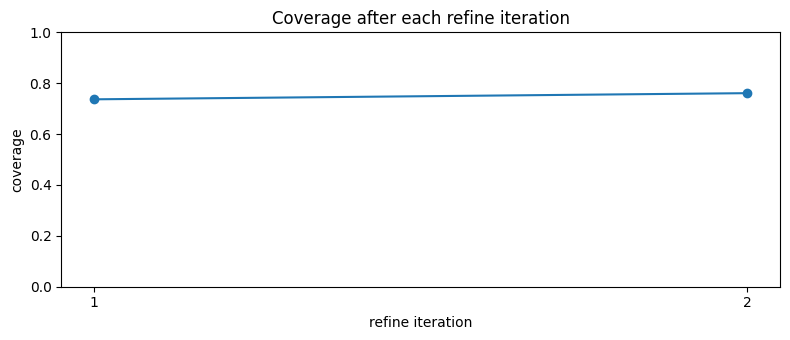

iteration 1: coverage 0.737  motifs 35  placements 1291
iteration 2: coverage 0.761  motifs 35  placements 1336


In [3]:
passes = summary["passes"]
outers = [row["outer"] for row in passes]
cover = [row["coverage"] for row in passes]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(outers, cover, marker="o", color="C0")
ax.set_xlabel("refine iteration")
ax.set_ylabel("coverage")
ax.set_ylim(0, 1)
ax.set_xticks(outers)
ax.set_title("Coverage after each refine iteration")
fig.tight_layout()
plt.show()
for row in passes:
    print(
        f"iteration {row['outer']}: coverage {row['coverage']:.3f}  "
        f"motifs {row['n_motifs']}  placements {row['n_placements']}"
    )


## How many times each column is covered

The histogram counts time columns. The limit `k` is 1, so a column is covered once or not at all.


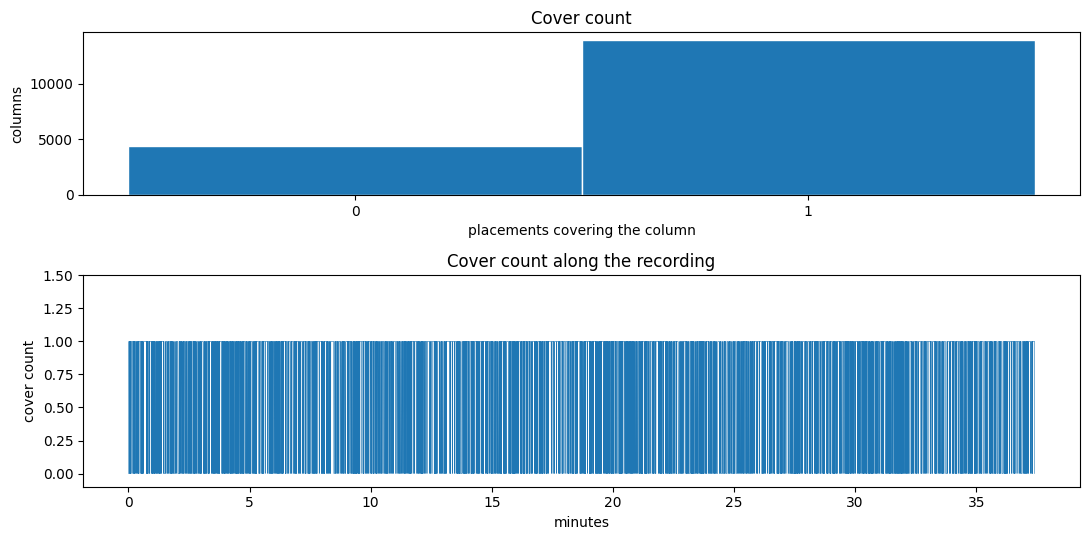

count 0: 4369 columns
count 1: 13901 columns


In [4]:
stacked = np.concatenate([counts[window.window_id] for window in windows])
minutes = np.arange(stacked.size) * sec_per_bin / 60.0
k = int(knobs["k"])
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), gridspec_kw={"height_ratios": [1, 1.3]})
bins = np.arange(-0.5, k + 1.5, 1)
axes[0].hist(stacked, bins=bins, color="C0", edgecolor="white")
axes[0].set_xticks(range(k + 1))
axes[0].set_xlabel("placements covering the column")
axes[0].set_ylabel("columns")
axes[0].set_title("Cover count")
axes[1].plot(minutes, stacked, color="C0", lw=0.4)
axes[1].set_xlabel("minutes")
axes[1].set_ylabel("cover count")
axes[1].set_ylim(-0.1, k + 0.5)
axes[1].set_title("Cover count along the recording")
fig.tight_layout()
plt.show()
for value in range(k + 1):
    print(f"count {value}: {int(np.sum(stacked == value))} columns")


## Placements per motif


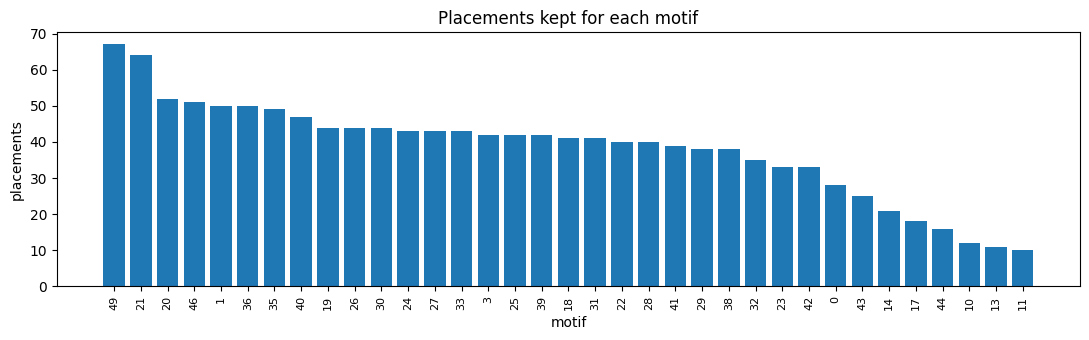

In [5]:
motifs = sorted(summary["motifs"], key=lambda row: -row["n_placements"])
names = [str(row["motif_id"]) for row in motifs]
heights = [row["n_placements"] for row in motifs]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(np.arange(len(names)), heights, color="C0")
ax.set_xticks(np.arange(len(names)), names, rotation=90, fontsize=8)
ax.set_xlabel("motif")
ax.set_ylabel("placements")
ax.set_title("Placements kept for each motif")
fig.tight_layout()
plt.show()


## Specificity

The dot-product sequence is shifted and scaled by a one-minute Gaussian before the peaks are measured. The number for a motif is the 90th percentile of its peak-to-baseline ratios on that sequence. The kernel is the leading component.


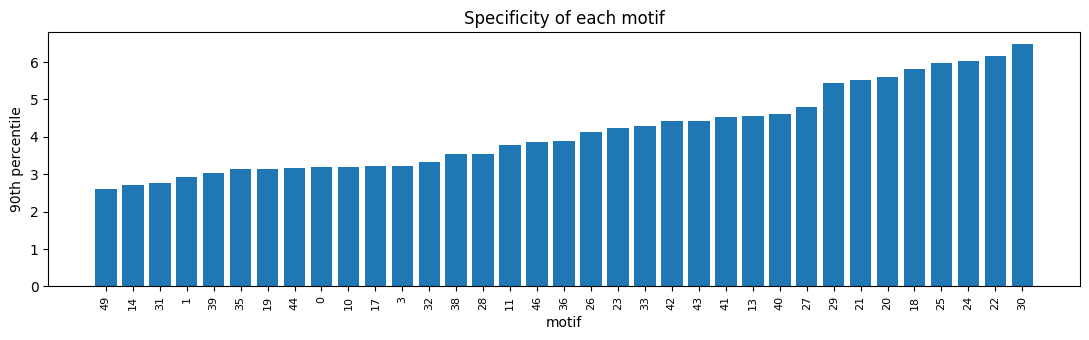

p90  min 2.598  max 6.472


In [6]:
spec = {row["motif_id"]: row for row in summary["specificity"]}
order = sorted(summary["motifs"], key=lambda row: spec[row["motif_id"]]["p90"])
labels = [str(row["motif_id"]) for row in order]
p90 = [spec[row["motif_id"]]["p90"] for row in order]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(np.arange(len(labels)), p90, color="C0")
ax.set_xticks(np.arange(len(labels)), labels, rotation=90, fontsize=8)
ax.set_xlabel("motif")
ax.set_ylabel("90th percentile")
ax.set_title("Specificity of each motif")
fig.tight_layout()
plt.show()
print(f"p90  min {min(p90):.3f}  max {max(p90):.3f}")


## Motifs

Each panel is the leading principal component, the cube root of its absolute value from about 12 Hz to 1500 Hz. The jet scale on each panel runs from that panel's 2nd percentile to its 98th. The title is the motif index and how many placements it kept. The saved atom has five components; this panel is component 0.


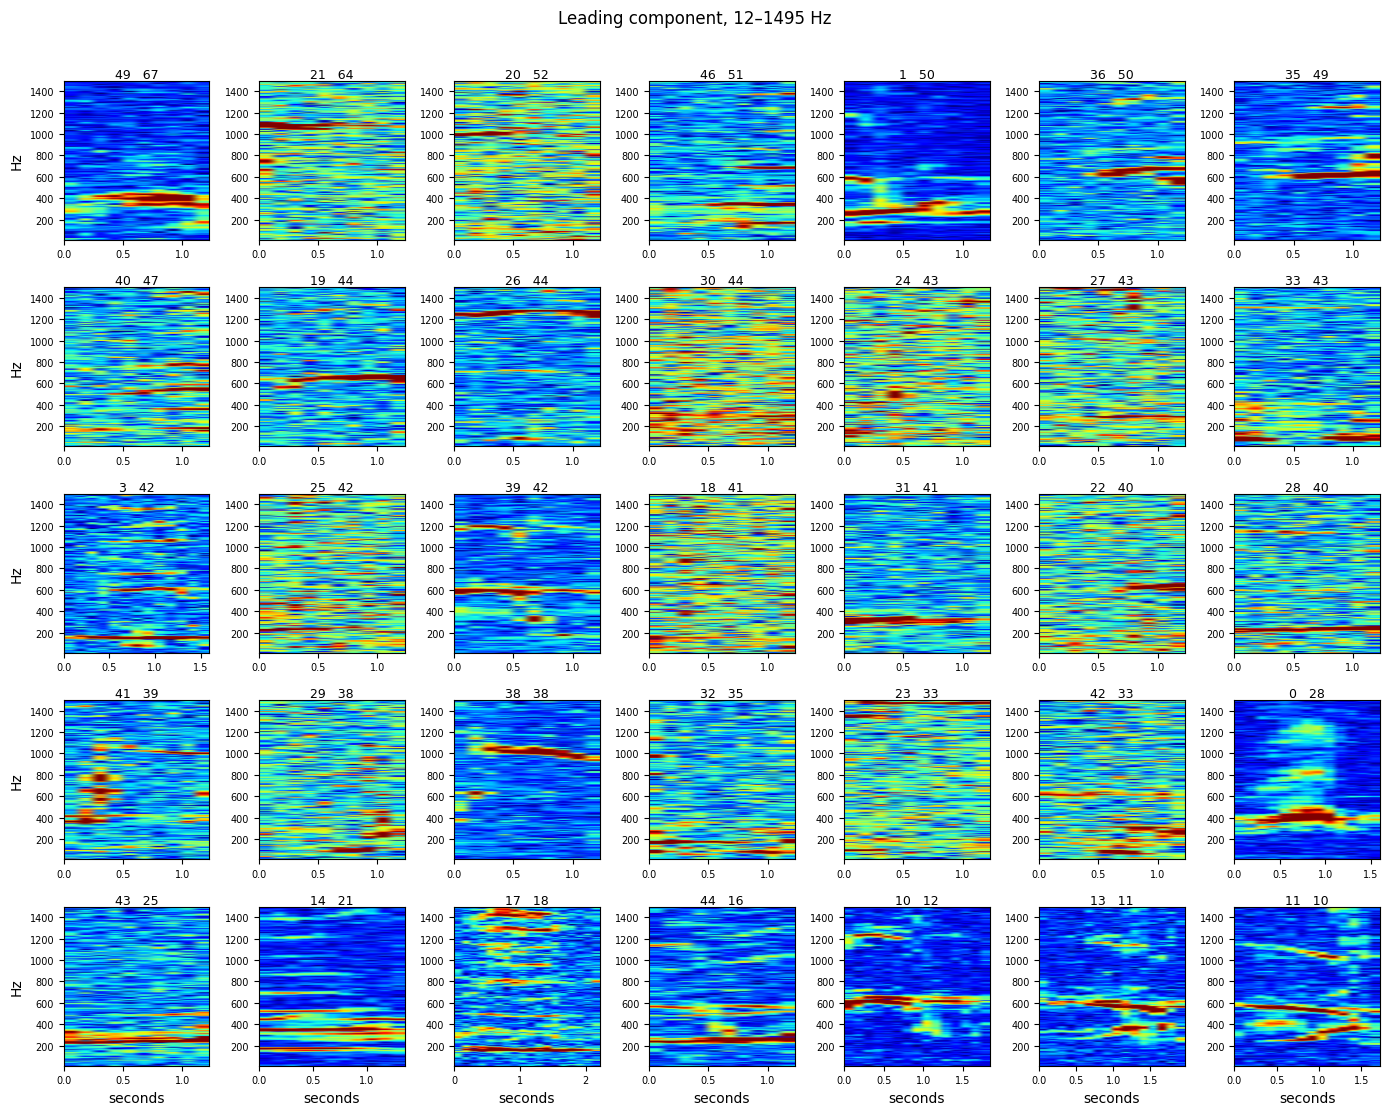

In [7]:
panels = []
for row in motifs:
    atom = np.load(OUT / row["path"])
    component = atom[0] if atom.ndim == 3 else atom
    panels.append((row, component))
ncols = 7
nrows = int(np.ceil(len(panels) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.2 * nrows))
axes = np.atleast_2d(axes)
for panel, (row, component) in enumerate(panels):
    r, c = divmod(panel, ncols)
    ax = axes[r, c]
    shown = display_from_spwhiten(component)[band_lo:band_hi]
    lo, hi = np.percentile(shown, [2, 98])
    if not np.isfinite(lo) or hi <= lo:
        lo, hi = float(np.min(shown)), float(np.max(shown))
    extent = [0.0, component.shape[1] * sec_per_bin, f_lo, f_hi]
    ax.imshow(shown, origin="lower", aspect="auto", cmap="jet", vmin=lo, vmax=hi, extent=extent)
    ax.set_title(f"{row['motif_id']}   {row['n_placements']}", fontsize=9, pad=2)
    ax.tick_params(labelsize=7)
    if c == 0:
        ax.set_ylabel("Hz")
    if r == nrows - 1:
        ax.set_xlabel("seconds")
for panel in range(len(panels), nrows * ncols):
    r, c = divmod(panel, ncols)
    axes[r, c].axis("off")
fig.suptitle(f"Leading component, {f_lo:.0f}–{f_hi:.0f} Hz", y=1.01)
fig.tight_layout()
plt.show()


## Two minutes with the most placements

The interval is the two-minute stretch that contains the most placement starts. Placements are ordered by their start column. The strip under the spectrogram marks each placement with a stable color for its motif. The grid is the recording at each placement, in that same order. The title of a panel is the motif index and the time from the start of the interval.


80 placements in columns 13417–14393  (27.48–29.48 min, 120.1 s)
order  motif  seconds  width  unexplained
    1    35      0.0   10  0.2314
    2     1      1.4   10  0.2702
    3    31      2.7   10  0.2239
    4    31      4.4   10  0.2114
    5    25      6.8   10  0.2072
    6    39      8.1   10  0.2263
    7    44      9.6   10  0.0015
    8    36     10.8   10  0.2126
    9     1     12.2   10  0.3005
   10    27     13.6   10  0.1870
   11    35     15.5   10  0.2200
   12    24     16.7   10  0.1031
   13    28     18.3   10  0.2004
   14    18     19.5   10  0.2022
   15    41     21.5   10  0.0784
   16    39     22.7   10  0.2152
   17     1     24.0   10  0.3417
   18    46     25.2   10  0.2394
   19    21     27.2   10  0.2060
   20    25     28.6   10  0.1293
   21    22     30.0   10  0.1875
   22    35     31.2   10  0.2087
   23    39     33.5   10  0.1755
   24    35     34.8   10  0.2144
   25    39     36.0   10  0.2408
   26    41     38.3   10  0.2284
   27    

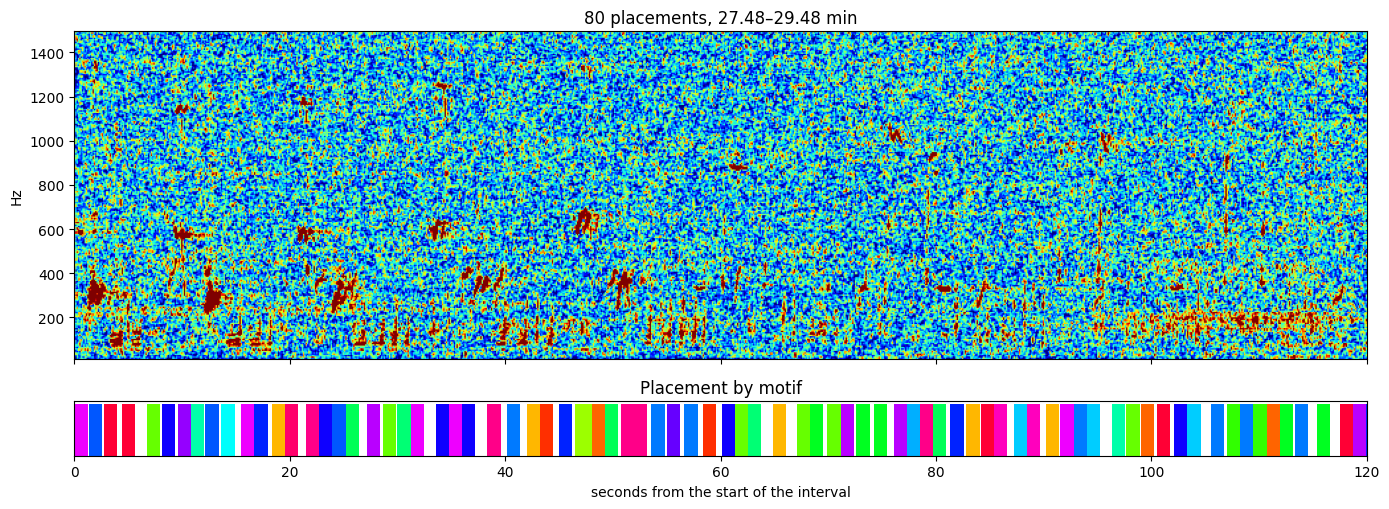

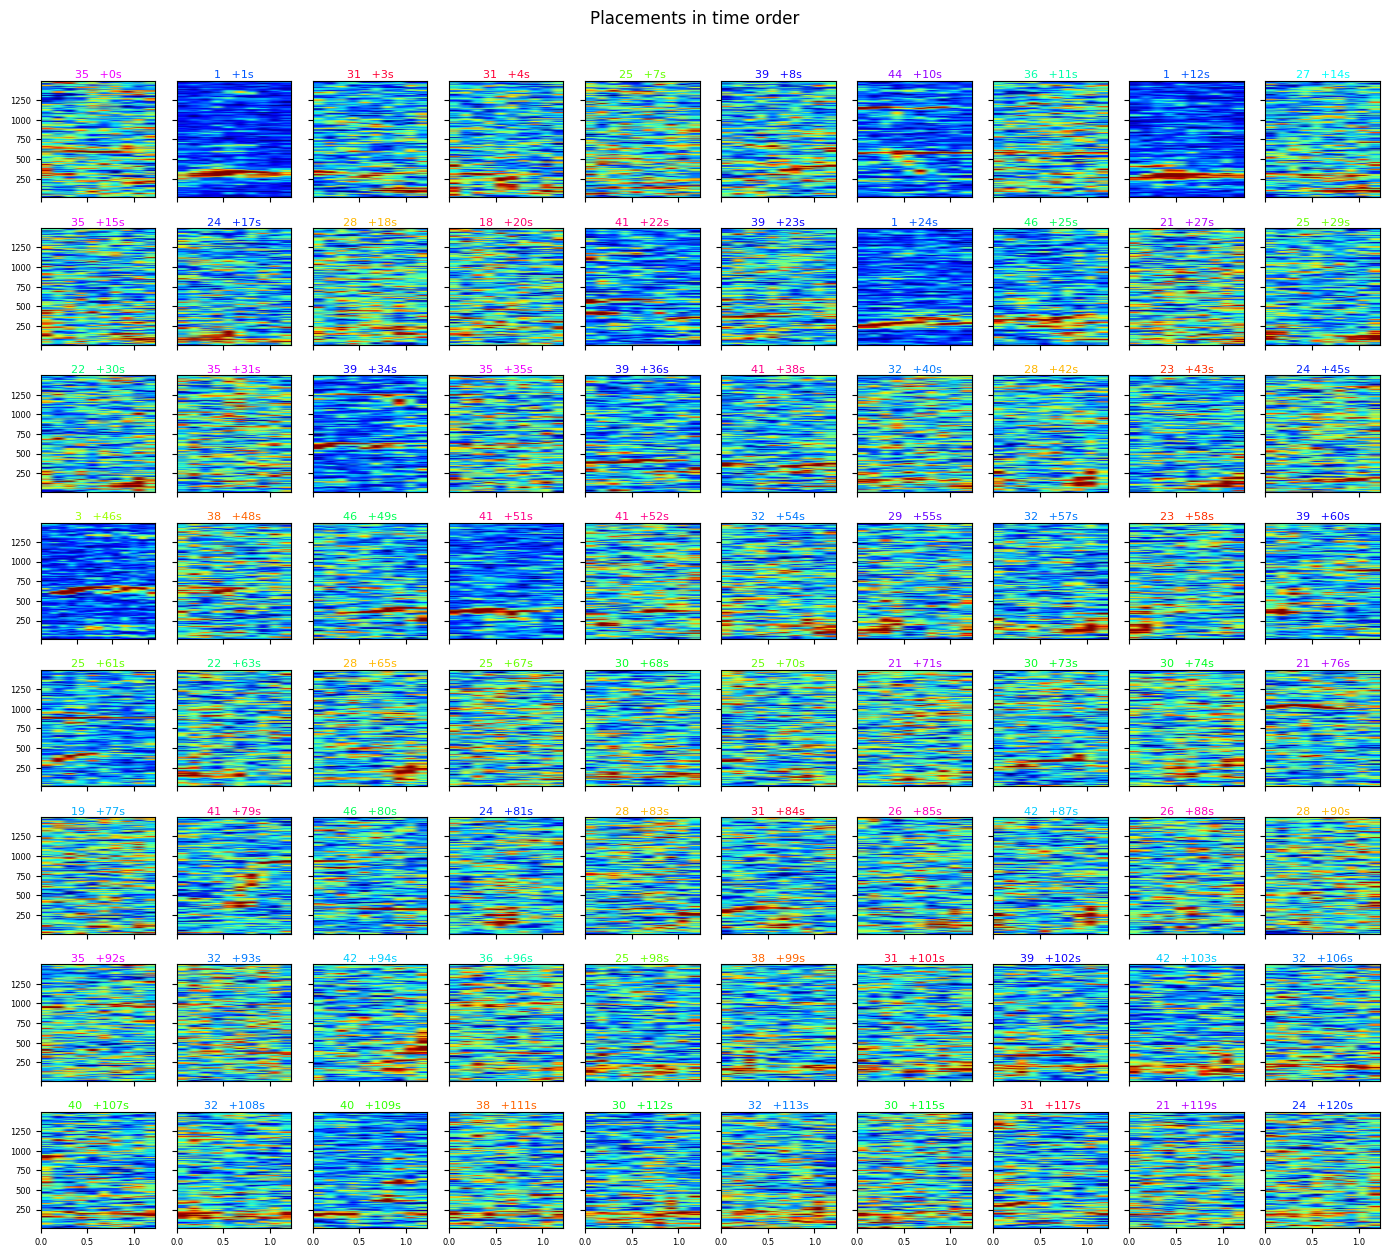

In [8]:
span = int(round(120.0 / sec_per_bin))
n_time = spectrogram.shape[1]
starts = np.array(
    [offsets[row["window_id"]] + int(row["t_start"]) for row in matchings], dtype=np.int64
)
hist = np.bincount(starts, minlength=n_time)
csum = np.cumsum(hist)
right = csum[span - 1 :]
left = np.concatenate([[0], csum[: n_time - span]])
origin = int(np.argmax(right - left))
chosen = [row for row, start in zip(matchings, starts) if origin <= start < origin + span]
chosen.sort(key=lambda row: offsets[row["window_id"]] + int(row["t_start"]))
t0 = origin * sec_per_bin
t1 = (origin + span) * sec_per_bin
print(
    f"{len(chosen)} placements in columns {origin}–{origin + span - 1}  "
    f"({t0 / 60.0:.2f}–{t1 / 60.0:.2f} min, {t1 - t0:.1f} s)"
)
print("order  motif  seconds  width  unexplained")
for index, row in enumerate(chosen, start=1):
    start = offsets[row["window_id"]] + int(row["t_start"])
    print(
        f"  {index:3d}  {row['motif_id']:4d}  {(start - origin) * sec_per_bin:7.1f}  "
        f"{row['width']:3d}  {row['unexplained']:.4f}"
    )
sequence = " ".join(str(row["motif_id"]) for row in chosen)
print("motif sequence")
print(sequence)

motif_ids = sorted(row["motif_id"] for row in summary["motifs"])
hues = (np.arange(len(motif_ids)) * 0.61803398875) % 1.0
palette = {motif_id: plt.cm.hsv(hue) for motif_id, hue in zip(motif_ids, hues)}

clip = display_from_spwhiten(spectrogram[band_lo:band_hi, origin : origin + span])
lo, hi = np.percentile(clip, [2, 98])
fig, axes = plt.subplots(
    2, 1, figsize=(14, 5.2), sharex=True, gridspec_kw={"height_ratios": [4.2, 0.7]}
)
extent = [0.0, span * sec_per_bin, f_lo, f_hi]
axes[0].imshow(clip, origin="lower", aspect="auto", cmap="jet", vmin=lo, vmax=hi, extent=extent)
axes[0].set_ylabel("Hz")
axes[0].set_title(
    f"{len(chosen)} placements, {t0 / 60.0:.2f}–{t1 / 60.0:.2f} min"
)
for row in chosen:
    start = offsets[row["window_id"]] + int(row["t_start"])
    x = (start - origin) * sec_per_bin
    width = row["width"] * sec_per_bin
    axes[1].bar(
        x, 1.0, width=width, align="edge", color=palette[row["motif_id"]], linewidth=0
    )
axes[1].set_xlim(0.0, span * sec_per_bin)
axes[1].set_yticks([])
axes[1].set_xlabel("seconds from the start of the interval")
axes[1].set_title("Placement by motif")
fig.tight_layout()
plt.show()

ncols = 10
nrows = int(np.ceil(len(chosen) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 1.55 * nrows))
axes = np.atleast_2d(axes)
for panel, row in enumerate(chosen):
    r, c = divmod(panel, ncols)
    ax = axes[r, c]
    start = offsets[row["window_id"]] + int(row["t_start"])
    patch = display_from_spwhiten(
        spectrogram[band_lo:band_hi, start : start + int(row["width"])]
    )
    plo, phi = np.percentile(patch, [2, 98])
    if not np.isfinite(plo) or phi <= plo:
        plo, phi = float(np.min(patch)), float(np.max(patch))
    extent = [0.0, row["width"] * sec_per_bin, f_lo, f_hi]
    ax.imshow(patch, origin="lower", aspect="auto", cmap="jet", vmin=plo, vmax=phi, extent=extent)
    ax.set_title(
        f"{row['motif_id']}   +{(start - origin) * sec_per_bin:.0f}s",
        fontsize=8,
        color=palette[row["motif_id"]],
        pad=2,
    )
    ax.tick_params(labelsize=6)
    if c != 0:
        ax.set_yticklabels([])
    if r != nrows - 1:
        ax.set_xticklabels([])
for panel in range(len(chosen), nrows * ncols):
    r, c = divmod(panel, ncols)
    axes[r, c].axis("off")
fig.suptitle("Placements in time order", y=1.01)
fig.tight_layout()
plt.show()
